In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511039/notebook

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511039/notebook


In [5]:
!python --version

Python 3.13.18


In [2]:
!pip freeze | grep -iE "^(opencv-python|opencv-python-headless|numpy|matplotlib|scikit-image|pandas|pillow)==" > ../requirements.txt
!cat ../requirements.txt

matplotlib==3.10.0
numpy==2.1.3
opencv-python==5.0.0.93
opencv-python-headless==5.0.0.93
pandas==2.2.3
pillow==11.3.0
scikit-image==0.25.2


In [4]:
import pandas as pd
label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby("kelas", sort=False)["persen_bercak"]
      .agg(["count", "mean", "min", "max"]).round(2))
print(label.groupby(["kelas", "kondisi_cahaya"], sort=False).size().unstack())

        count  mean   min   max
kelas                          
sehat      20  0.00  0.00  0.00
ringan     20  0.33  0.11  0.70
berat      20  5.51  2.76  9.09
kondisi_cahaya  normal  gelap  terang  kontras_rendah  bayangan
kelas                                                          
sehat                4      4       4               4         4
ringan               4      4       4               4         4
berat                4      4       4               4         4


OpenCV 4.14.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 17 254
piksel (y=100, x=200) dalam urutan BGR: [150 182 206]


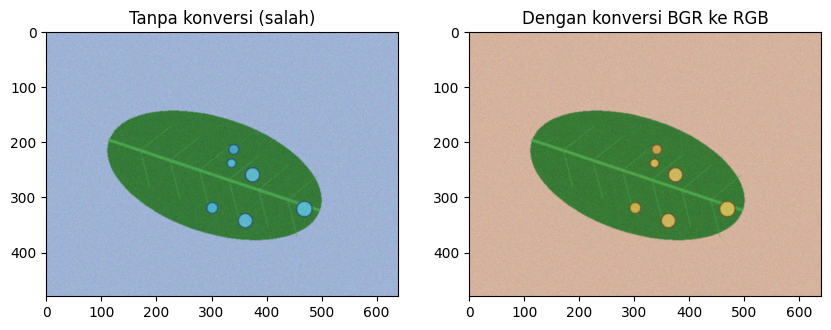

In [3]:
import sys
sys.path.append("../src")
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil

print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB"); plt.savefig("../hasil/b1_bgr_rgb.png")